In [ ]:
from prettytable import PrettyTable

def bfs(graph, start_state, goal_state):
  output = PrettyTable(["X", "Success status", "S"])
  queue = []
  visited = set()
  queue.append(start_state)
  while queue:
    s = queue.pop(0)
    if s == goal_state:
      output.add_row([s, True, queue])
      return output


    if graph.get(s):
      queue_for_output = []
      for i in graph.get(s):
        queue_for_output.append(i)
        if i not in visited:
          queue.append(i)
          visited.add(i)

      output.add_row([s, False, queue_for_output])

  return output

def random_search(graph, start_state, goal_state):
  output = PrettyTable(["X", "Success status", "S", "X'"])
  S = set()
  S.add(start_state)
  x_bar = start_state
  output.add_row([start_state, False, S, x_bar])
  while S or x_bar:
    initial_node = x_bar
    print(initial_node)
    if initial_node == goal_state:
      output.add_row([initial_node, True, S, x_bar])
      return output
    else:
      if initial_node:
        S.clear()
      # get neighbors
      if graph.get(initial_node):
        for val in graph.get(initial_node):
          S.add(val)
      if S:
        x_bar = S.pop()
      output.add_row([initial_node, False, S, x_bar])

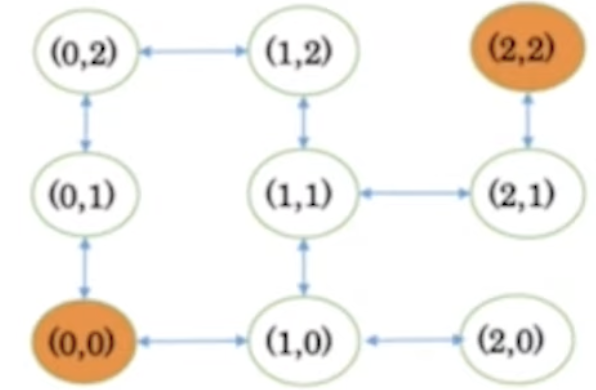

In [ ]:
from collections import defaultdict
class Graph:
  def __init__(self):
    self.graph = defaultdict(list)
  def addEdge(self, u, v):
    self.graph[u].append(v)
  def getGraph(self):
    return self.graph



graph = Graph()
graph.addEdge((0,0),(1,0))
graph.addEdge((0,0),(0,1))
graph.addEdge((0,1),(0,2))
graph.addEdge((0,1),(0,0))
graph.addEdge((0,2),(1,2))
graph.addEdge((0,2),(0,1))
graph.addEdge((1,2),(1,1))
graph.addEdge((1,2),(0,2))
graph.addEdge((1,1),(1,2))
graph.addEdge((1,1),(2,1))
graph.addEdge((1,1),(1,0))
graph.addEdge((1,0),(2,0))
graph.addEdge((1,0),(0,0))
graph.addEdge((1,0),(1,1))
graph.addEdge((2,1),(2,2))
graph.addEdge((2,2),(2,1))
graph.addEdge((2,1),(1,1))
graph.addEdge((2,0),(1,0))
graph.addEdge((1,0),(1,1))
graph.addEdge((1,0),(0,0))

# output = random_search(graph.getGraph(), (0,0), (2,2))
# print(output)

output = bfs(graph.getGraph(), (0,0), (2,2))
print(output)

+--------+----------------+------------------------------------------+
|   X    | Success status |                    S                     |
+--------+----------------+------------------------------------------+
| (0, 0) |     False      |             [(1, 0), (0, 1)]             |
| (1, 0) |     False      | [(2, 0), (0, 0), (1, 1), (1, 1), (0, 0)] |
| (0, 1) |     False      |             [(0, 2), (0, 0)]             |
| (2, 0) |     False      |                 [(1, 0)]                 |
| (0, 0) |     False      |             [(1, 0), (0, 1)]             |
| (1, 1) |     False      |         [(1, 2), (2, 1), (1, 0)]         |
| (0, 2) |     False      |             [(1, 2), (0, 1)]             |
| (1, 2) |     False      |             [(1, 1), (0, 2)]             |
| (2, 1) |     False      |             [(2, 2), (1, 1)]             |
| (2, 2) |      True      |                    []                    |
+--------+----------------+------------------------------------------+


In [ ]:
from collections import deque


def BFS(a, b, target):

    m = {}
    isSolvable = False
    path = []


    q = []

    q.append((0, 0))

    while (len(q) > 0):
        u = q.pop()# If this state is already visited
        if ((u[0], u[1]) in m):
            continue
        if ((u[0] > a or u[1] > b or
             u[0] < 0 or u[1] < 0)):
            continue

        # Filling the vector for constructing
        # the solution path
        path.append([u[0], u[1]])

        # Marking current state as visited
        m[(u[0], u[1])] = 1

        # If we reach solution state, put ans=1
        if (u[0] == target or u[1] == target):
            isSolvable = True

            if (u[0] == target):
                if (u[1] != 0):

                    # Fill final state
                    path.append([u[0], 0])
            else:
                if (u[0] != 0):

                    # Fill final state
                    path.append([0, u[1]])

            # Print the solution path
            sz = len(path)
            for i in range(sz):
                print("(", path[i][0], ",",
                      path[i][1], ")")
            break

        # If we have not reached final state
        # then, start developing intermediate
        # states to reach solution state
        q.append([u[0], b])  # Fill Jug2
        q.append([a, u[1]])  # Fill Jug1

        for ap in range(max(a, b) + 1):

            # Pour amount ap from Jug2 to Jug1
            c = u[0] + ap
            d = u[1] - ap

            # Check if this state is possible or not
            if (c == a or (d == 0 and d >= 0)):
                q.append([c, d])

            # Pour amount ap from Jug 1 to Jug2
            c = u[0] - ap
            d = u[1] + ap

            # Check if this state is possible or not
            if ((c == 0 and c >= 0) or d == b):
                q.append([c, d])

        # Empty Jug2
        q.append([a, 0])

        # Empty Jug1
        q.append([0, b])

    # No, solution exists if ans=0
    if (not isSolvable):
        print("No solution")


# Driver code
Jug1, Jug2, target = 4, 3, 2
print("Path from initial state to solution state ::")

BFS(Jug1, Jug2, target)

Path from initial state to solution state ::
( 0 , 0 )
( 0 , 3 )
( 4 , 0 )
( 1 , 3 )
( 4 , 3 )
( 3 , 0 )
( 3 , 3 )
( 4 , 2 )
( 0 , 2 )


In [ ]:
# DETECT LOOP WITH DFS

# Adjacency List
adj=[]

# Function to add edge u --> v
def addEdge (u, v):
    adj[u].append(v)

# Helper function to check for cycle.
def checkCycleUtil (node, visited, inStack):
    # Check if node exists in the
    # recursive stack.
    if (inStack[node] == True):
        return True

    # Check if node is already visited.
    if (visited[node] == True):
        return False

    # Marking node as visited.
    visited[node] = True

    # Marking node to be present in
    # recursive stack.
    inStack[node] = True

    # Iterate for all adjacent of
    # 'node'.
    for v in adj[node]:
        # Recurse for 'v'.
        if (checkCycleUtil(v, visited, inStack) == True):
            return True


    # Mark 'node' to be removed
    # from the recursive stack.
    inStack[node] = False

    # Return false if no cycle exists.
    return False

# Function to check for the cycle.
def checkCycle(V, E):
    # Defining visited and inStack array
    # to keep track of visited vertices
    # and vertices in Recursive stack.
    visited = [False] * V
    inStack = [False] * V

    # Iterating for i = 0 To i = V - 1
    # to detect cycle in different
    # DFS trees.
    for i in range(V):
        # Check if cycle exists.
        if (checkCycleUtil(i, visited, inStack) == True):
            return True


    # Returning false, if no cycle is found.
    return False

# Defining the number of Vertices
# and the number of edges.
V, E = 5, 7

# Defining Adjacency List
adj = [[] for i in range(V)]
# Building the Graph same as example 1.
addEdge(0, 1)
addEdge(1, 0)
addEdge(0, 4)
addEdge(0, 2)
addEdge(1, 3)
addEdge(2, 3)
addEdge(4, 1)
addEdge(4, 2)

# If the graph contains cycle
# Print YES
if(checkCycle(V, E)):
    print("YES")
# Otherwise Print NO
else:
    print("NO")

YES


In [ ]:
# DETECT LOOP USING BFS
# Adjacency List
adj=[]

# Function to add edge u --> v
def addEdge (u, v):
    adj[u].append(v)

# Function to check for the cycle.
def checkCycle (V, E):
    # Defining the array to
    # store indegrees.
    deg = [0]*V

    # Computing indegree of
    # each vertex using.
    for i in range(V):
        for x in adj[i]:
            deg[x] += 1

    # Queue to store vertices
    # with  having 0 indegree.
    q = []

    # Iterate from i = 0 To i
    # = V - 1 and find vertices
    # having indegree as 0.
    for i in range(V):
        if (deg[i] == 0):
            q.append(i)

    # Defining the counter.
    counter = 0

    # Iterating while the queue is
    # not empty.
    while (q):
        # Dequeue from 'q'.
        u = q.pop(0)

        # Increase the counter.
        counter += 1

        # Iterate for all neighours
        # of vertex 'u'.
        for v in adj[u]:
            # Decrease the indegree.
            deg[v] -= 1

            # If deg[v] is 0, insert
            # it the q.
            if (deg[v] == 0):
                q.append(v)

    # Returning true if counter != V.
    return counter != V


# Defining the number of Vertices
# and the number of edges.
V, E = 5, 7

# Defining Adjacency List
adj = [[] for i in range(V)]
# Building the Graph same as example 1.
addEdge(0, 1)
addEdge(0, 4)
addEdge(0, 2)
addEdge(1, 3)
addEdge(2, 3)
addEdge(4, 1)
addEdge(4, 2)

# If the graph contains cycle
# Print YES
if(checkCycle(V, E)):
    print("YES")
# Otherwise Print NO
else:
    print("NO")

NO


In [ ]:
class Graph:
    def __init__(self,V): # Constructor
        self.V = V        # No. of vertices
        self.adj  = [[] for i in range(V)]  # adjacency lists

    def addEdge(self,v, w):     # to add an edge to graph
        self.adj[v].append(w)    # Add w to v’s list.


    # prints all not yet visited vertices reachable from s
    def DFS(self,s):            # prints all vertices in DFS manner from a given source.
                                # Initially mark all vertices as not visited
        visited = [False for i in range(self.V)]

        # Create a stack for DFS
        stack = []

        # Push the current source node.
        stack.append(s)

        while (len(stack)):
            # Pop a vertex from stack and print it
            s = stack[-1]
            stack.pop()

            # Stack may contain same vertex twice. So
            # we need to print the popped item only
            # if it is not visited.
            if (not visited[s]):
                print(s,end=' ')
                visited[s] = True

            # Get all adjacent vertices of the popped vertex s
            # If a adjacent has not been visited, then push it
            # to the stack.
            for node in self.adj[s]:
                if (not visited[node]):
                    stack.append(node)



# Driver program to test methods of graph class

g = Graph(5); # Total 5 vertices in graph
g.addEdge(1, 0);
g.addEdge(0, 2);
g.addEdge(2, 1);
g.addEdge(0, 3);
g.addEdge(1, 4);

print("Following is Depth First Traversal")
g.DFS(0)

Following is Depth First Traversal
0 3 2 1 4 

In [ ]:
from collections import defaultdict
class Graph:
  def __init__(self):
    self.graph = defaultdict(list)
  def addEdge(self, u, v):
    self.graph[u].append(v)
  def getGraph(self):
    return self.graph

# run dfs and bfs alternately
def algo(graph, visited, start_node, goal_node):
  queue = []
  dfs = True
  is_goal = start_node == goal_node
  queue.append(start_node)
  while queue:
    print('current queue', queue)

    s = queue.pop(0) if not dfs else queue.pop()
    if dfs:
      print('getting this out by dfs', s)
    else:
      print('getting this out by bfs', s)

    print('Visited so far ', visited)
    if not s in visited:
      print('traversed', s)
      is_goal =  s == goal_node
      if is_goal:
        print('Reached GOAL')
        visited.add(s)
        return True

      visited.add(s)

    if graph.get(s):
      for i in graph.get(s):
        if i not in visited:
          queue.append(i)




    dfs = not dfs




graph = Graph()
graph.addEdge((0,0),(1,0))
graph.addEdge((0,0),(0,1))
graph.addEdge((0,1),(0,2))
graph.addEdge((0,1),(0,0))
graph.addEdge((0,2),(1,2))
graph.addEdge((0,2),(0,1))
graph.addEdge((1,2),(1,1))
graph.addEdge((1,2),(0,2))
graph.addEdge((1,1),(1,2))
graph.addEdge((1,1),(2,1))
graph.addEdge((1,1),(1,0))
graph.addEdge((1,0),(2,0))
graph.addEdge((1,0),(0,0))
graph.addEdge((2,1),(2,2))
graph.addEdge((2,2),(2,1))
graph.addEdge((2,1),(1,1))
graph.addEdge((2,0),(1,0))
graph.addEdge((1,0),(1,1))
graph.addEdge((1,0),(0,0))

# output = random_search(graph.getGraph(), (0,0), (2,2))
# print(output)

visited = set()
is_goal = False
for node in graph.getGraph():
  if not node in visited:
    p = algo(graph.getGraph(), visited, node, (2,2))
    if p:
      break

# (0, 0) (1, 0) (0, 1) (2, 0) (0, 0) (1, 1) (0, 2) (1, 2) (2, 1) (2, 2)
# (0, 0) (0, 1) (0, 2) (1, 2) (1, 1) (1, 0) (2, 0) (2, 1) (2, 2) Mixed

# (0, 0) (1, 0) (1, 1) (0, 1) (0, 2) (2, 0) (1, 2) (2, 1) (2, 2) Mixed with dfs true start

# (0, 0) (0, 1) (1, 0) (1, 1) (0, 2) (1, 2) (2, 0) (2, 1) (2, 2) Mixed with bfs true start

# (0, 0) (1, 0) (0, 1) (2, 0) (1, 1) (0, 2) (1, 2) (2, 1) (2, 2) BFS
# (0, 0) (0, 1) (0, 2) (1, 2) (1, 1) (1, 0) (2, 0) (2, 1) (2, 2) DFS



graph = Graph()
graph.addEdge('S','A')
graph.addEdge('S','B')
graph.addEdge('S','C')
graph.addEdge('A','S')
graph.addEdge('A','E')
graph.addEdge('B','S')
graph.addEdge('B','E')
graph.addEdge('B','D')
graph.addEdge('C','S')
graph.addEdge('C','D')
graph.addEdge('E','A')
graph.addEdge('E','B')
graph.addEdge('E','F')
graph.addEdge('D','B')
graph.addEdge('D','C')
graph.addEdge('D','F')
graph.addEdge('F','E')
graph.addEdge('F','D')
graph.addEdge('F','G')
graph.addEdge('G','F')

print('\n')
visited = set()
for node in graph.getGraph():
  if not node in visited:
    p = algo(graph.getGraph(), visited, node, 'G')
    if p:
      break


current queue [(0, 0)]
getting this out by dfs (0, 0)
Visited so far  set()
traversed (0, 0)
current queue [(1, 0), (0, 1)]
getting this out by bfs (1, 0)
Visited so far  {(0, 0)}
traversed (1, 0)
current queue [(0, 1), (2, 0), (1, 1)]
getting this out by dfs (1, 1)
Visited so far  {(1, 0), (0, 0)}
traversed (1, 1)
current queue [(0, 1), (2, 0), (1, 2), (2, 1)]
getting this out by bfs (0, 1)
Visited so far  {(1, 0), (1, 1), (0, 0)}
traversed (0, 1)
current queue [(2, 0), (1, 2), (2, 1), (0, 2)]
getting this out by dfs (0, 2)
Visited so far  {(1, 0), (0, 1), (1, 1), (0, 0)}
traversed (0, 2)
current queue [(2, 0), (1, 2), (2, 1), (1, 2)]
getting this out by bfs (2, 0)
Visited so far  {(0, 1), (0, 0), (1, 1), (0, 2), (1, 0)}
traversed (2, 0)
current queue [(1, 2), (2, 1), (1, 2)]
getting this out by dfs (1, 2)
Visited so far  {(0, 1), (0, 0), (1, 1), (2, 0), (0, 2), (1, 0)}
traversed (1, 2)
current queue [(1, 2), (2, 1)]
getting this out by bfs (1, 2)
Visited so far  {(0, 1), (1, 2), (0, 

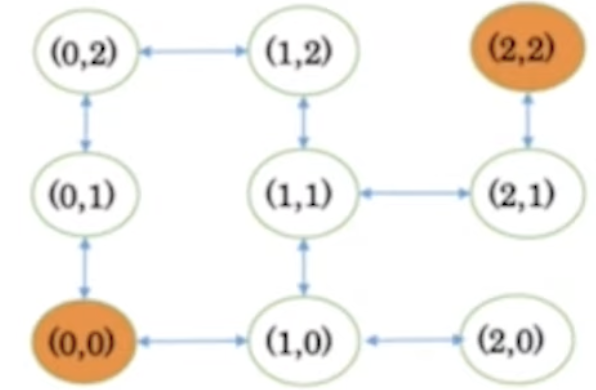


```
current queue [(0, 0)]
getting this out by dfs (0, 0)
traversed (0, 0)
current queue [(1, 0), (0, 1)]
getting this out by bfs (1, 0)
traversed (1, 0)
current queue [(0, 1), (2, 0), (1, 1)]
getting this out by dfs (1, 1)
traversed (1, 1)
current queue [(0, 1), (2, 0), (1, 2), (2, 1)]
getting this out by bfs (0, 1)
traversed (0, 1)
current queue [(2, 0), (1, 2), (2, 1), (0, 2)]
getting this out by dfs (0, 2)
traversed (0, 2)
current queue [(2, 0), (1, 2), (2, 1), (1, 2)]
getting this out by bfs (2, 0)
traversed (2, 0)
current queue [(1, 2), (2, 1), (1, 2)]
getting this out by dfs (1, 2)
traversed (1, 2)
current queue [(1, 2), (2, 1)]
getting this out by bfs (1, 2)
current queue [(2, 1)]
getting this out by dfs (2, 1)
traversed (2, 1)
current queue [(2, 2)]
getting this out by bfs (2, 2)
traversed (2, 2)
```



In [ ]:
from collections import defaultdict
import random
class Graph:
  def __init__(self):
    self.graph = defaultdict(list)
  def addEdge(self, u, v):
    self.graph[u].append(v)
  def getGraph(self):
    return self.graph


# run rs and bfs alternately
def algo(graph, visited, start_node, goal_node):
  queue = []
  rs = True
  is_goal = start_node == goal_node
  queue.append(start_node)
  while queue:
    print('current queue', queue)
    s = queue.pop(random.randrange(len(queue)) if rs else 0)

    if rs:
      print('getting this out by RS', s)
    else:
      print('getting this out by BFS', s)

    print('Visited so far ', visited)
    if not s in visited:
      print('traversed', s)
      is_goal =  s == goal_node
      if is_goal:
        print('Reached GOAL')
        visited.add(s)
        return True

      visited.add(s)

    if graph.get(s):
      for i in graph.get(s):
        if i not in visited:
          queue.append(i)




    rs = not rs




graph = Graph()
graph.addEdge((0,0),(1,0))
graph.addEdge((0,0),(0,1))
graph.addEdge((0,1),(0,2))
graph.addEdge((0,1),(0,0))
graph.addEdge((0,2),(1,2))
graph.addEdge((0,2),(0,1))
graph.addEdge((1,2),(1,1))
graph.addEdge((1,2),(0,2))
graph.addEdge((1,1),(1,2))
graph.addEdge((1,1),(2,1))
graph.addEdge((1,1),(1,0))
graph.addEdge((1,0),(2,0))
graph.addEdge((1,0),(0,0))
graph.addEdge((2,1),(2,2))
graph.addEdge((2,2),(2,1))
graph.addEdge((2,1),(1,1))
graph.addEdge((2,0),(1,0))
graph.addEdge((1,0),(1,1))
graph.addEdge((1,0),(0,0))

# output = random_search(graph.getGraph(), (0,0), (2,2))
# print(output)

visited = set()
is_goal = False
for node in graph.getGraph():
  if not node in visited:
    p = algo(graph.getGraph(), visited, node, (2,2))
    if p:
      break

# (0, 0) (1, 0) (0, 1) (2, 0) (0, 0) (1, 1) (0, 2) (1, 2) (2, 1) (2, 2)
# (0, 0) (0, 1) (0, 2) (1, 2) (1, 1) (1, 0) (2, 0) (2, 1) (2, 2) Mixed

# (0, 0) (1, 0) (1, 1) (0, 1) (0, 2) (2, 0) (1, 2) (2, 1) (2, 2) Mixed with dfs true start

# (0, 0) (0, 1) (1, 0) (1, 1) (0, 2) (1, 2) (2, 0) (2, 1) (2, 2) Mixed with bfs true start

# (0, 0) (1, 0) (0, 1) (2, 0) (1, 1) (0, 2) (1, 2) (2, 1) (2, 2) BFS
# (0, 0) (0, 1) (0, 2) (1, 2) (1, 1) (1, 0) (2, 0) (2, 1) (2, 2) DFS



graph = Graph()
graph.addEdge('S','A')
graph.addEdge('S','B')
graph.addEdge('S','C')
graph.addEdge('A','S')
graph.addEdge('A','E')
graph.addEdge('B','S')
graph.addEdge('B','E')
graph.addEdge('B','D')
graph.addEdge('C','S')
graph.addEdge('C','D')
graph.addEdge('E','A')
graph.addEdge('E','B')
graph.addEdge('E','F')
graph.addEdge('D','B')
graph.addEdge('D','C')
graph.addEdge('D','F')
graph.addEdge('F','E')
graph.addEdge('F','D')
graph.addEdge('F','G')
graph.addEdge('G','F')

print('\n')
visited = set()
for node in graph.getGraph():
  if not node in visited:
    p = algo(graph.getGraph(), visited, node, 'G')
    if p:
      break




current queue [(0, 0)]
getting this out by RS (0, 0)
Visited so far  set()
traversed (0, 0)
current queue [(1, 0), (0, 1)]
getting this out by BFS (1, 0)
Visited so far  {(0, 0)}
traversed (1, 0)
current queue [(0, 1), (2, 0), (1, 1)]
getting this out by RS (0, 1)
Visited so far  {(1, 0), (0, 0)}
traversed (0, 1)
current queue [(2, 0), (1, 1), (0, 2)]
getting this out by BFS (2, 0)
Visited so far  {(1, 0), (0, 1), (0, 0)}
traversed (2, 0)
current queue [(1, 1), (0, 2)]
getting this out by RS (0, 2)
Visited so far  {(1, 0), (0, 1), (2, 0), (0, 0)}
traversed (0, 2)
current queue [(1, 1), (1, 2)]
getting this out by BFS (1, 1)
Visited so far  {(0, 1), (0, 0), (2, 0), (0, 2), (1, 0)}
traversed (1, 1)
current queue [(1, 2), (1, 2), (2, 1)]
getting this out by RS (1, 2)
Visited so far  {(0, 1), (0, 0), (1, 1), (2, 0), (0, 2), (1, 0)}
traversed (1, 2)
current queue [(1, 2), (2, 1)]
getting this out by BFS (1, 2)
Visited so far  {(0, 1), (1, 2), (0, 0), (1, 1), (2, 0), (0, 2), (1, 0)}
current 

In [ ]:
# Using Breadth first search according to pseudo code in Norvig for finding
# the solution path for the 8 - puzzle problem

class Problem:
  def __init__(self):
    pass

  def __search_zero(self, state):
    for i in range(0, len(state)):
      for j in range(0, len(state)):
        if state[i][j] == 0:
          return (i, j)

  def INITIAL_STATE(self):
    return ((7,2,4),(5,0,6),(8,3,1))

  def GOALTEST(self, input_state):
    return input_state == ((0,1,2),(3,4,5),(6,7,8))

  def RESULT(self, state, action):
    if not action and not state:
      return self.INITIAL_STATE()

    grid = [list(state[0]), list(state[1]), list(state[2])]

    i, j = self.__search_zero(state)
    n_i, n_j = i + action[0], j + action[1]
    if 0 <= n_i <= 2 and 0 <= n_j <= 2:
      grid[i][j], grid[n_i][n_j] = grid[n_i][n_j], grid[i][j]
      return (tuple(grid[0]), tuple(grid[1]), tuple(grid[2]))

    return None

  def actions(self, state):
    if not state:
      return []
    i, j = self.__search_zero(state)
    if i == 0 and j == 0:
      return [(1, 0), (0, -1)]
    if i == 2 and j == 0:
      return [(0, 1), (1, 0)]
    if i == 0 and j == 2:
      return [(-1, 0), (0, -1)]
    if i == 2 and j == 2:
      return [(0, 1), (-1, 0)]
    return [(-1, 0), (1, 0), (0, 1), (0, -1)]



class ChildNode:
  def __init__(self, problem, parent, action):
    self.state = problem.RESULT(parent.state, action) if parent else problem.RESULT(parent, action)
    self.parent = parent
    self.action = action


def solution(node):
  print('Found solution')
  result = []
  result.append(node)
  node = node.parent
  while node:
    result.append(node)
    node = node.parent

  return result

def bfs(problem):
  frontier = []
  explored = set()
  frontier.append(ChildNode(problem, None, None))
  while frontier:
    node = frontier.pop(0)
    if problem.GOALTEST(node.state):
      print('Total explored nodes ', len(explored))
      return solution(node)


    explored.add(node.state)

    for action in problem.actions(node.state):
      child = ChildNode(problem, node, action)
      if not child.state in explored:
        if problem.GOALTEST(child.state):
          print('Total explored nodes ', len(explored))
          return solution(child)
        frontier.append(child)

problem = Problem()
solution = bfs(problem)


print('Solution path length ',len(solution))
action_dict = {
    (-1, 0): 'MOVED 1 CELL UP',
    (1, 0): 'MOVED 1 CELL BOTTOM',
    (0, 1): 'MOVED 1 CELL RIGHT',
    (0, -1): 'MOVED 1 CELL LEFT',
    None: 'NO MOVEMENT'
}
for node in solution[::-1]:
  print('state = ', node.state, 'from previous state ', action_dict[node.action])



Total explored nodes  143184
Found solution
Solution path length  33
state =  ((7, 2, 4), (5, 0, 6), (8, 3, 1)) from previous state  NO MOVEMENT
state =  ((7, 0, 4), (5, 2, 6), (8, 3, 1)) from previous state  MOVED 1 CELL UP
state =  ((0, 7, 4), (5, 2, 6), (8, 3, 1)) from previous state  MOVED 1 CELL LEFT
state =  ((5, 7, 4), (0, 2, 6), (8, 3, 1)) from previous state  MOVED 1 CELL BOTTOM
state =  ((5, 7, 4), (2, 0, 6), (8, 3, 1)) from previous state  MOVED 1 CELL RIGHT
state =  ((5, 0, 4), (2, 7, 6), (8, 3, 1)) from previous state  MOVED 1 CELL UP
state =  ((0, 5, 4), (2, 7, 6), (8, 3, 1)) from previous state  MOVED 1 CELL LEFT
state =  ((2, 5, 4), (0, 7, 6), (8, 3, 1)) from previous state  MOVED 1 CELL BOTTOM
state =  ((2, 5, 4), (8, 7, 6), (0, 3, 1)) from previous state  MOVED 1 CELL BOTTOM
state =  ((2, 5, 4), (8, 7, 6), (3, 0, 1)) from previous state  MOVED 1 CELL RIGHT
state =  ((2, 5, 4), (8, 7, 6), (3, 1, 0)) from previous state  MOVED 1 CELL RIGHT
state =  ((2, 5, 4), (8, 7, 0)

In [ ]:
# Using Breadth first search according to pseudo code in Norvig for finding
# the solution path for the Tic tac toe problem

class Problem:
  def __init__(self):
    pass

  def __get_player(self, state):
    filled_cells = 0
    for i in range(0, len(state)):
      for j in range(0, len(state)):
        if state[i][j] != '':
          filled_cells += 1
    return 'x' if filled_cells % 2 != 0 else 'o'

  def __return_empty_cells(self, state):
    empty_cells = []
    for i in range(0, len(state)):
      for j in range(0, len(state)):
        if state[i][j] == '':
          empty_cells.append((i, j))

    return empty_cells

  def INITIAL_STATE(self):
    return (('','',''),('','',''),('','',''))

  def GOALTEST(self, input_state):
    # return input_state == (('x','o','o'),('x','o',''),('x','',''))

    # if any one of the players x or o wins, goal would be achieved
    for player in ['x','o']:
      # check rows
      for row in range(0, len(input_state)):
        row_match = True
        for col in range(0, len(input_state)):
          row_match = row_match and input_state[row][col] == player

        if row_match:
          return True

      # check cols
      for col in range(0, len(input_state)):
        col_match = True
        for row in range(0, len(input_state)):
          col_match = col_match and input_state[row][col] == player

        if col_match:
          return True

      # check diagonals
      left_diag = True
      right_diag = True
      for index in range(0, len(input_state)):
        left_diag = left_diag and input_state[index][index] == player
      if left_diag:
        return True

      for index in range(len(input_state) - 1, -1, -1):
        right_diag = right_diag and input_state[index][index] == player
      if right_diag:
        return True


  def RESULT(self, state, action):
    if not action and not state:
      return self.INITIAL_STATE()

    grid = [list(state[0]), list(state[1]), list(state[2])]
    i, j = action
    grid[i][j] = self.__get_player(state)
    return (tuple(grid[0]), tuple(grid[1]), tuple(grid[2]))

  def actions(self, state):
    if not state:
      return []
    return self.__return_empty_cells(state)



class ChildNode:
  def __init__(self, problem, parent, action):
    self.state = problem.RESULT(parent.state, action) if parent else problem.RESULT(parent, action)
    self.parent = parent
    self.action = action


def solution(node):
  print('In solution')
  result = []
  result.append(node.state)
  node = node.parent
  while node:
    result.append(node.state)
    node = node.parent

  return result

def bfs(problem):
  frontier = []
  explored = set()
  frontier.append(ChildNode(problem, None, None))
  while frontier:
    node = frontier.pop(0)
    if problem.GOALTEST(node.state):
      print('Total explored nodes ', len(explored))
      return solution(node)


    explored.add(node.state)

    for action in problem.actions(node.state):
      child = ChildNode(problem, node, action)
      if not child.state in explored:
        if problem.GOALTEST(child.state):
          print('Total explored nodes ', len(explored))
          return solution(child)
        frontier.append(child)

problem = Problem()
solution = bfs(problem)

print('Solution path length ',len(solution))
for node in solution[::-1]:
  print(node)

Total explored nodes  341
In solution
Solution path length  6
(('', '', ''), ('', '', ''), ('', '', ''))
(('o', '', ''), ('', '', ''), ('', '', ''))
(('o', 'x', ''), ('', '', ''), ('', '', ''))
(('o', 'x', ''), ('o', '', ''), ('', '', ''))
(('o', 'x', 'x'), ('o', '', ''), ('', '', ''))
(('o', 'x', 'x'), ('o', '', ''), ('o', '', ''))


In [ ]:
# Using Breadth first search according to pseudo code in Norvig for finding
# the solution path for the Water container problem

class Problem:
  def __init__(self):
    pass


  def INITIAL_STATE(self):
    return (0,0)

  def GOALTEST(self, input_state):
    if not input_state:
      return False
    x, y = input_state

    return x == 4 or y == 4

  def RESULT(self, state, action):
    if not action and not state:
      return self.INITIAL_STATE()

    i, j = state
    n_i, n_j = i + action[0], j + action[1]
    if n_i <= 5 and n_j <= 3:
      n_i = 0 if n_i < 0 else n_i
      n_j = 0 if n_j < 0 else n_j
      return (n_i, n_j)

    return None

  def actions(self, state):

    if not state:
      return []

    c1, c2 = state

    actions = []

    if c1 > 0:
      actions.append((-c1, 0))
    if c2 > 0:
      actions.append((0, -c2))
    if 0 <= c1 < 5:
      actions.append((5 - c1, 0))
    if 0 <= c2 < 3:
      actions.append((0, 3 - c2))

    if 0 < c1 <= 5 and 0 <= c2 < 3 :
      offset = min(c1 - c2, c2 - c1)
      actions.append((-offset, offset))
    if 0 <= c1 < 5 and 0 < c2 <= 3 :
      offset = min(c1 - c2, c2 - c1)
      actions.append((-offset, offset))

    return actions



class ChildNode:
  def __init__(self, problem, parent, action):
    self.state = problem.RESULT(parent.state, action) if parent else problem.RESULT(parent, action)
    self.parent = parent
    self.action = action


def solution(node):
  print('Found solution')
  result = []
  result.append(node)
  node = node.parent
  while node:
    result.append(node)
    node = node.parent

  return result

def bfs(problem):
  frontier = []
  explored = set()
  frontier.append(ChildNode(problem, None, None))
  while frontier:
    node = frontier.pop(0)
    if problem.GOALTEST(node.state):
      print('Total explored nodes ', len(explored))
      return solution(node)


    explored.add(node.state)
    print(explored)

    for action in problem.actions(node.state):
      child = ChildNode(problem, node, action)
      if not child.state in explored:
        if problem.GOALTEST(child.state):
          print('Total explored nodes ', len(explored))
          return solution(child)
        frontier.append(child)


problem = Problem()
solution = bfs(problem)


print('Solution path length ',len(solution))
for node in solution[::-1]:
  print(node.state)

{(0, 0)}
{(5, 0), (0, 0)}
{(0, 3), (5, 0), (0, 0)}
{(5, 3), (0, 3), (5, 0), (0, 0)}
{(0, 0), (0, 3), (5, 0), (5, 3), None}
{(0, 0), (0, 3), (5, 0), (5, 3), None}
{(0, 0), (0, 3), (3, 0), (5, 0), (5, 3), None}
{(0, 0), (0, 3), (3, 0), (3, 3), (5, 0), (5, 3), None}


TypeError: ignored

In [ ]:
from queue import PriorityQueue


def ucs(root, goal):
    """
    Return the uniform cost search path from root to gaol.

    Args:
        root: the starting node for the search
        goal: the goal node for the search

    Returns: a list with the path from root to goal

    Raises: ValueError if goal isn't in the graph
    """
    # create a priority queue of paths
    queue = PriorityQueue()
    queue.put((0, [root]))
    # iterate over the items in the queue
    while not queue.empty():
        # get the highest priority item
        pair = queue.get()
        current = pair[1][-1]
        # if it's the goal, return
        if current.label == goal:
            return pair[1]
        # add all the edges to the priority queue
        for edge in current.children:
            # create a new path with the node from the edge
            new_path = list(pair[1])
            new_path.append(edge.destination)
            # append the new path to the queue with the edges priority
            queue.put((pair[0] + edge.cost, new_path))

In [ ]:
class Node(object):
    """This class represents a node in a graph."""

    def __init__(self, label: str=None):
        """
        Initialize a new node.

        Args:
            label: the string identifier for the node
        """
        self.label = label
        self.children = []

    def __lt__(self,other):
        """
        Perform the less than operation (self < other).

        Args:
            other: the other Node to compare to
        """
        return (self.label < other.label)

    def __gt__(self,other):
        """
        Perform the greater than operation (self > other).

        Args:
            other: the other Node to compare to
        """
        return (self.label > other.label)

    def __repr__(self):
        """Return a string form of this node."""
        return '{} -> {}'.format(self.label, self.children)

    def add_child(self, node, cost=1):
        """
        Add a child node to this node.

        Args:
            node: the node to add to the children
            cost: the cost of the edge (default 1)
        """
        edge = Edge(self, node, cost)
        self.children.append(edge)


class Edge(object):
    """This class represents an edge in a graph."""

    def __init__(self, source: Node, destination: Node, cost: int=1):
        """
        Initialize a new edge.

        Args:
            source: the source of the edge
            destination: the destination of the edge
            cost: the cost of the edge (default 1)
        """
        self.source = source
        self.destination = destination
        self.cost = cost

    def __repr__(self):
        """Return a string form of this edge."""
        return '{}: {}'.format(self.cost, self.destination.label)

In [ ]:
S = Node('S')
A = Node('A')
B = Node('B')
C = Node('C')
D = Node('D')
G = Node('G')

S.add_child(A, 1)
S.add_child(G, 12)

A.add_child(B, 3)
A.add_child(C, 1)

B.add_child(D, 3)

C.add_child(D, 1)
C.add_child(G, 2)

D.add_child(G, 3)


_ = [print(node) for node in [S, A, B, C, D, G]]

S -> [1: A, 12: G]
A -> [3: B, 1: C]
B -> [3: D]
C -> [1: D, 2: G]
D -> [3: G]
G -> []


In [ ]:
ucs(S, 'G')

[S -> [1: A, 12: G], A -> [3: B, 1: C], C -> [1: D, 2: G], G -> []]

In [ ]:
from heapq import heappush, heappop

class PriorityQueue:

    def __init__(self, iterable=[]):
        self.heap = []
        for value in iterable:
            heappush(self.heap, (0, value))

    def add(self, value, priority=0):
        heappush(self.heap, (priority, value))

    def pop(self):
        priority, value = heappop(self.heap)
        return value

    def __len__(self):
        return len(self.heap)

def get_heuristic(grid):
    """
    >>> f = get_heuristic([[0, 0], [0, 0]])
    >>> f((0, 0))
    1
    >>> f((0, 1))
    1
    >>> f((1, 1))
    0
    """
    M, N = len(grid), len(grid[0])
    (a, b) = goal_cell = (M - 1, N - 1)
    def get_clear_path_distance_from_goal(cell):
        (i, j) = cell
        return max(abs(a - i), abs(b - j))
    return get_clear_path_distance_from_goal

def get_successor_function(grid):
    """
    >>> f = get_successor_function([[0, 0, 0], [0, 1, 0], [1, 0, 0]])
    >>> sorted(f((1, 2)))
    [(0, 1), (0, 2), (2, 1), (2, 2)]
    >>> sorted(f((2, 1)))
    [(1, 0), (1, 2), (2, 2)]
    """
    def get_clear_adjacent_cells(cell):
        i, j = cell
        return (
            (i + a, j + b)
            for a in (-1, 0, 1)
            for b in (-1, 0, 1)
            if a != 0 or b != 0
            if 0 <= i + a < len(grid)
            if 0 <= j + b < len(grid[0])
            if grid[i + a][j + b] == 0
        )
    return get_clear_adjacent_cells

def get_goal_function(grid):
    """
    >>> f = get_goal_function([[0, 0], [0, 0]])
    >>> f((0, 0))
    False
    >>> f((0, 1))
    False
    >>> f((1, 1))
    True
    """
    M = len(grid)
    N = len(grid[0])
    def is_bottom_right(cell):
        return cell == (M-1, N-1)
    return is_bottom_right

def a_star_graph_search(
            start,
            goal_function,
            successor_function,
            heuristic
	):
    visited = set()
    came_from = dict()
    distance = {start: 0}
    frontier = PriorityQueue()
    frontier.add(start)
    while frontier:
        node = frontier.pop()
        if node in visited:
            continue
        if goal_function(node):
            return reconstruct_path(came_from, start, node)
        visited.add(node)
        for successor in successor_function(node):
            frontier.add(
                successor,
                priority = distance[node] + 1 + heuristic(successor)
            )
            if (successor not in distance
                or distance[node] + 1 < distance[successor]):
                distance[successor] = distance[node] + 1
                came_from[successor] = node
    return None

def reconstruct_path(came_from, start, end):
    """
    >>> came_from = {'b': 'a', 'c': 'a', 'd': 'c', 'e': 'd', 'f': 'd'}
    >>> reconstruct_path(came_from, 'a', 'e')
    ['a', 'c', 'd', 'e']
    """
    reverse_path = [end]
    while end != start:
        end = came_from[end]
        reverse_path.append(end)
    return list(reversed(reverse_path))


grid = [
	[0,0,0,1,0,0,1,0],
	[0,0,0,0,0,0,0,0],
	[1,0,0,1,1,0,1,0],
	[0,1,1,1,0,0,0,0],
	[0,0,0,0,0,1,1,1],
	[1,0,1,0,0,0,0,0],
	[1,1,0,0,0,1,0,0],
	[0,0,0,0,0,1,0,0]
]
shortest_path = a_star_graph_search(
    start              = (0, 0),
    goal_function      = get_goal_function(grid),
    successor_function = get_successor_function(grid),
    heuristic          = get_heuristic(grid)
)
if shortest_path is None or grid[0][0] == 1:
    print('No solution')
else:
    print(shortest_path)

[(0, 0), (1, 1), (2, 2), (1, 3), (1, 4), (2, 5), (3, 4), (4, 4), (5, 5), (6, 6), (7, 7)]


In [ ]:
from heapq import heappush, heappop

class PriorityQueue:

    def __init__(self, iterable=[]):
        self.heap = []
        for value in iterable:
            heappush(self.heap, (0, value))

    def add(self, value, priority=0):
        heappush(self.heap, (priority, value))

    def pop(self):
        priority, value = heappop(self.heap)
        return value

    def __len__(self):
        return len(self.heap)

class Problem:
  def __init__(self):
    pass

  def __search_one(self, state):
    for i in range(0, len(state)):
      for j in range(0, len(state)):
        if state[i][j] == 1:
          return (i, j)

  def INITIAL_STATE(self):
    return ((1,0,0),(0,0,0),(0,0,0))

  def GOALTEST(self, input_state):
    return input_state == ((0,0,0),(0,0,0),(0,0,1))

  def STEP_COST(self, input_state, action):
    M, N = len(input_state), len(input_state)
    (a, b) = goal_cell = (M - 1, N - 1)
    (i, j) = action
    return max(abs(a - i), abs(b - j))

  def RESULT(self, state, action):
    if not action and not state:
      return self.INITIAL_STATE()

    grid = [list(state[0]), list(state[1]), list(state[2])]

    i, j = self.__search_zero(state)
    n_i, n_j = i + action[0], j + action[1]
    if 0 <= n_i <= 2 and 0 <= n_j <= 2:
      grid[i][j], grid[n_i][n_j] = grid[n_i][n_j], grid[i][j]
      return (tuple(grid[0]), tuple(grid[1]), tuple(grid[2]))

    return None

  def actions(self, state):
    if not state:
      return []
    i, j = self.__search_one(state)
    if i == 0 and j == 0:
      return [(1, 0), (0, -1)]
    if i == 2 and j == 0:
      return [(0, 1), (1, 0)]
    if i == 0 and j == 2:
      return [(-1, 0), (0, -1)]
    if i == 2 and j == 2:
      return [(0, 1), (-1, 0)]
    return [(-1, 0), (1, 0), (0, 1), (0, -1)]



class ChildNode:
  def __init__(self, problem, parent, action):
    self.state = problem.RESULT(parent.state, action) if parent else problem.RESULT(parent, action)
    self.parent = parent
    self.action = action
    self.path_cost = parent.path_cost + problem.STEP_COST(parent.state, action)


def solution(node):
  print('Found solution')
  result = []
  result.append(node)
  node = node.parent
  while node:
    result.append(node)
    node = node.parent

  return result

def a_star(problem):
  frontier = PriorityQueue()
  explored = set()
  frontier.add(ChildNode(problem, None, None))
  while frontier:
    node = frontier.pop(0)
    if problem.GOALTEST(node.state):
      print('Total explored nodes ', len(explored))
      return solution(node)


    explored.add(node.state)

    for action in problem.actions(node.state):
      child = ChildNode(problem, node, action)
      if not child.state in explored:
        if problem.GOALTEST(child.state):
          print('Total explored nodes ', len(explored))
          return solution(child)
        frontier.append(child)

problem = Problem()
solution = a_star(problem)


print('Solution path length ',len(solution))
action_dict = {
    (-1, 0): 'MOVED 1 CELL UP',
    (1, 0): 'MOVED 1 CELL BOTTOM',
    (0, 1): 'MOVED 1 CELL RIGHT',
    (0, -1): 'MOVED 1 CELL LEFT',
    None: 'NO MOVEMENT'
}
for node in solution[::-1]:
  print('state = ', node.state, 'from previous state ', action_dict[node.action])

In [ ]:
def players(s):
    pass

def actions(s):
    pass

def result(s, a):
    pass

def terminal_test(s):
    pass

def utility(s, p):
    pass

def minimax(s):
    if terminal_test(s):
        return utility(s)

    if players(s) == 'MAX':
        v = float('-inf')
        for a in actions(s):
            v = max(v, minimax(result(s, a)))
        return v

    if players(s) == 'MIN':
        v = float('inf')
        for a in actions(s):
            v = min(v, minimax(result(s, a)))
        return v

# argmax function
def argmax(vector):
    index, value = 0, vector[0]
    for i,v in enumerate(vector):
    if v > value:
        index, value = i,v
    return index

def min_value(state):
    if terminal_test(state):
        return utility(state)
    v = float('-inf')
    for a in actions(state):
        v = max(v, max_value(result(state, a)))
    return v

def max_value(state):
    if terminal_test(state):
        return utility(state)
    v = float('inf')
    for a in actions(state):
        v = min(v, min_value(result(state, a)))
    return v

def minimax_decision(state):
    # return action
    a = argmax(actions(state))
    return min_value(result(s, a))